Yolo Means You only Look Once


In [1]:
# %pip install ultralytics matplotlib opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 7.7 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import json

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
INPUT_IMAGE = "images2.jpeg"          # <- change to your image file path
OUTPUT_IMAGE = "output_annotated.jpg"
MODEL_NAME = "yolo26n.pt"         # yolov8n, yolov8s, yolov8m, etc.yolo26n
CONF_THRESH = 0.50
IMGSZ = 640

In [4]:
model = YOLO(MODEL_NAME)  # downloads weights automatically if needed
print("Loaded model:", MODEL_NAME)
print("Available classes (partial):", {k: v for k, v in list(model.names.items())[:10]})

Loaded model: yolo26n.pt
Available classes (partial): {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light'}


In [5]:
results = model.predict(source=INPUT_IMAGE, imgsz=IMGSZ, conf=CONF_THRESH, save=False)
res = results[0]   # first (and only) image result


image 1/1 /content/images2.jpeg: 448x640 1 person, 1 dog, 1 backpack, 17.3ms
Speed: 95.9ms preprocess, 17.3ms inference, 47.3ms postprocess per image at shape (1, 3, 448, 640)


In [6]:
# cell
detections = []
for box in res.boxes:
    # xyxy, conf, cls are available on each box
    xyxy = box.xyxy.cpu().numpy().tolist()[0]   # [x1, y1, x2, y2]
    conf = float(box.conf.cpu().numpy()[0]) if hasattr(box, "conf") else float(box.conf)
    cls_idx = int(box.cls.cpu().numpy()[0]) if hasattr(box, "cls") else int(box.cls)
    label = model.names.get(cls_idx, str(cls_idx))
    detections.append({
        "label": label,
        "class_id": cls_idx,
        "confidence": round(conf, 4),
        "x1": int(xyxy[0]),
        "y1": int(xyxy[1]),
        "x2": int(xyxy[2]),
        "y2": int(xyxy[3]),
    })

df = pd.DataFrame(detections)
if df.empty:
    print("No detections above confidence threshold.")
else:
    display(df)   # in Jupyter this shows a nice table

,label,class_id,confidence,x1,y1,x2,y2
0,person,0,0.9207,1359,68,1737,1069
1,dog,16,0.8614,1129,625,1314,1129
2,backpack,24,0.6244,1456,241,1654,569


Annotated image saved to: output_annotated.jpg


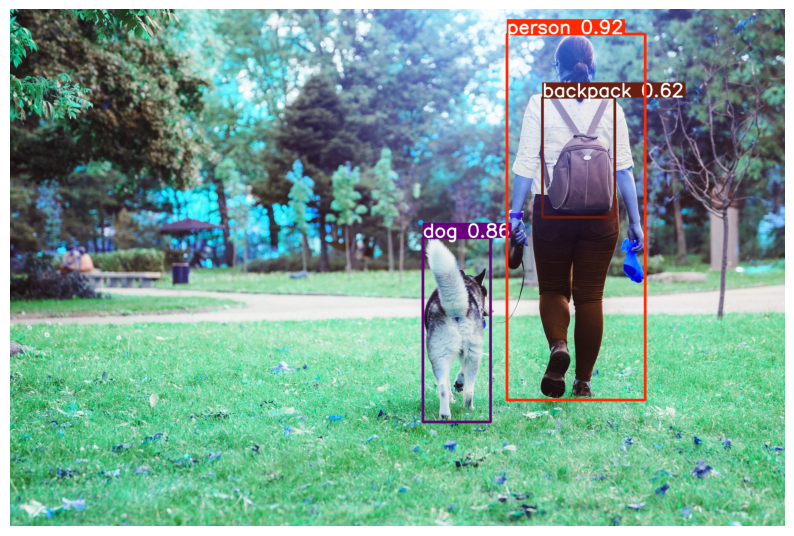

In [7]:
annotated_rgb = res.plot()  # returns an RGB numpy array with drawn boxes/labels
# convert RGB -> BGR for OpenCV saving
annotated_bgr = cv2.cvtColor(annotated_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(OUTPUT_IMAGE, annotated_bgr)
print("Annotated image saved to:", OUTPUT_IMAGE)

# Show inline (convert back to RGB for matplotlib)
img_show = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 10))
plt.imshow(img_show)
plt.axis("off")
plt.show()

In [8]:
# cell
out_json = {"input": INPUT_IMAGE, "output": OUTPUT_IMAGE, "detections": detections}
with open("detection_results.json", "w") as f:
    json.dump(out_json, f, indent=2)
print("Saved detection_results.json")

Saved detection_results.json


### Creating the Streamlit Application File

We will write a complete, robust, and heavily commented Streamlit application to a file named `app.py`.

In [ ]:
%%writefile app.py
import streamlit as st
import cv2
import numpy as np
from ultralytics import YOLO
from PIL import Image
import json

# st.set_page_config configures the page title, icon, and layout
st.set_page_config(
    page_title="YOLO Object Detection Hub",
    page_icon="🎯",
    layout="wide"
)

# st.title displays a large header title for the application
st.title("🎯 YOLO Object Detection App")

# st.markdown allows us to write formatted descriptive text using Markdown syntax
st.markdown("""
This app uses the **Ultralytics YOLO** model to detect objects in uploaded images.
Adjust the parameters on the sidebar, upload your image, and view results instantly!
""")

# st.sidebar creates a side panel where we can group configuration inputs
st.sidebar.header("⚙️ Model Configuration")

# st.sidebar.text_input lets the user type in the specific YOLO model weight name
model_name = st.sidebar.text_input(
    label="YOLO Model Name",
    value="yolo26n.pt",
    help="Specify any YOLOv8/YOLO11 weights file (e.g., yolo26n.pt, yolov8n.pt)"
)

# st.sidebar.slider provides a visual slider to set the detection confidence threshold
conf_threshold = st.sidebar.slider(
    label="Confidence Threshold",
    min_value=0.0,
    max_value=1.0,
    value=0.50,
    step=0.05,
    help="Only detections with confidence above this value will be shown"
)

# st.sidebar.select_slider lets the user select from specific predefined image size steps
img_size = st.sidebar.select_slider(
    label="Inference Image Size (imgsz)",
    options=[320, 416, 512, 640, 800, 1024],
    value=640,
    help="Image size to resize to before running inference"
)

# st.cache_resource ensures the model is loaded only once and cached for performance
@st.cache_resource
def load_model(name):
    try:
        return YOLO(name)
    except Exception as e:
        st.error(f"Failed to load model {name}: {e}")
        return None

# Load the configured model
model = load_model(model_name)

# st.file_uploader lets users upload files (like PNG/JPG/JPEG images)
uploaded_file = st.file_uploader(
    label="📤 Upload an Image",
    type=["jpg", "jpeg", "png"],
    help="Choose a local image file to analyze"
)

if uploaded_file is not None and model is not None:
    # Read the file uploaded by the user into a format compatible with OpenCV
    file_bytes = np.asarray(bytearray(uploaded_file.read()), dtype=np.uint8)
    opencv_image = cv2.imdecode(file_bytes, 1) # BGR

    # Convert BGR (OpenCV) to RGB for Streamlit/Matplotlib compatibility
    rgb_image = cv2.cvtColor(opencv_image, cv2.COLOR_BGR2RGB)

    # st.columns splits the screen layout into side-by-side columns
    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Original Image")
        # st.image renders images directly onto the web interface
        st.image(rgb_image, use_container_width=True)

    with st.spinner("Running detection..."): # st.spinner shows a loading animation while code executes
        # Run prediction on the input image
        results = model.predict(source=opencv_image, imgsz=img_size, conf=conf_threshold, save=False)
        res = results[0]

        # Render annotated detections onto a new RGB image
        annotated_rgb = res.plot()

        # Collect detections in structured format
        detections = []
        for box in res.boxes:
            xyxy = box.xyxy.cpu().numpy().tolist()[0]
            conf = float(box.conf.cpu().numpy()[0]) if hasattr(box, "conf") else float(box.conf)
            cls_idx = int(box.cls.cpu().numpy()[0]) if hasattr(box, "cls") else int(box.cls)
            label = model.names.get(cls_idx, str(cls_idx))
            detections.append({
                "label": label,
                "class_id": cls_idx,
                "confidence": round(conf, 4),
                "bbox": [int(xyxy[0]), int(xyxy[1]), int(xyxy[2]), int(xyxy[3])]
            })

    with col2:
        st.subheader("Processed Image")
        st.image(annotated_rgb, use_container_width=True)

    st.subheader("📊 Detection Results")

    if len(detections) > 0:
        # st.dataframe displays interactive tables (Pandas DataFrames)
        import pandas as pd
        st.dataframe(pd.DataFrame(detections), use_container_width=True)

        # Convert detections data into JSON string format for downloading
        json_string = json.dumps(detections, indent=2)

        # st.download_button allows the user to save output files locally
        st.download_button(
            label="💾 Download Detections as JSON",
            data=json_string,
            file_name="detections.json",
            mime="application/json"
        )
    else:
        # st.info is used to present useful status information to the user
        st.info("No targets detected above the selected confidence threshold.")
else:
    if model is None:
        st.warning("Waiting for a valid YOLO model to load...")
    else:
        st.info("Please upload an image to begin object detection.")


### How to Run Your Streamlit App

To run your newly created Streamlit app inside your local environment, run:
```bash
streamlit run app.py
```
